# 04.01 Document Inventory and Validation

**Phase 04 — Document Processing & OCR**  
**Objective:** Discover, inventory, and validate all supporting document files (images and PDFs), extract metadata, detect exact duplicates via SHA-256 hashing, flag corrupt/unreadable files, and export reproducible document-level audit tables without modifying raw source files.

### Execution Order & Contract
- **Inputs:** `data/raw/supporting document/supporting_docu/` (read-only) and optional `storage/uploads/originals/`.
- **Outputs:**
  - `data/interim/document_processing/document_inventory_manifest.csv`
  - `data/interim/document_processing/document_quality_audit.json`


### 1. Environment Setup & Project Root Resolution


In [1]:
import os
import sys
import json
import hashlib
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

def _find_root(p: Path = Path.cwd()) -> Path:
    for parent in [p.resolve(), *p.resolve().parents]:
        if (parent / 'data').exists() and (parent / 'experiments').exists():
            return parent
    return p.resolve()

PROJECT_ROOT = _find_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.document_processing import DocumentProcessingPaths
paths = DocumentProcessingPaths(PROJECT_ROOT)

SUPPORTED_IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SUPPORTED_PDF_EXTS = {'.pdf'}
SUPPORTED_EXTS = SUPPORTED_IMAGE_EXTS | SUPPORTED_PDF_EXTS

INVENTORY_CSV = paths.doc_inventory_manifest
AUDIT_JSON = paths.interim_doc_proc / 'document_quality_audit.json'
INVENTORY_CSV.parent.mkdir(parents=True, exist_ok=True)

print(f"Project Root        : {paths.root}")
print(f"Raw Documents Dir   : {paths.raw_documents_dir} (exists={paths.raw_documents_dir.exists()})")
print(f"Inventory Output    : {INVENTORY_CSV}")
print(f"Quality Audit JSON  : {AUDIT_JSON}")


Project Root        : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2
Raw Documents Dir   : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\raw\supporting document\supporting_docu (exists=True)
Inventory Output    : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\document_inventory_manifest.csv
Quality Audit JSON  : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\document_quality_audit.json


### 2. File Discovery, Integrity Checks & Metadata Extraction


In [2]:
def compute_sha256(file_path: Path, chunk_size: int = 65536) -> str:
    h = hashlib.sha256()
    with open(file_path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def inspect_document_file(file_path: Path, root_dir: Path) -> dict:
    ext = file_path.suffix.lower()
    rel_path = str(file_path.relative_to(root_dir)).replace('\\', '/')
    file_size = file_path.stat().st_size if file_path.exists() else 0
    parent_cat = file_path.parent.name
    capture_mode = file_path.parent.parent.name if file_path.parent.parent != root_dir else 'unknown'

    record = {
        'document_id': f"DOC_{hashlib.md5(rel_path.encode('utf-8')).hexdigest()[:8].upper()}",
        'filename': file_path.name,
        'relative_path': rel_path,
        'document_category': parent_cat,
        'capture_mode': capture_mode,
        'file_extension': ext,
        'file_size_bytes': int(file_size),
        'sha256': '',
        'is_supported_type': ext in SUPPORTED_EXTS,
        'is_readable': False,
        'width': 0,
        'height': 0,
        'channels': 0,
        'aspect_ratio': 0.0,
        'blur_laplacian_var': 0.0,
        'mean_brightness': 0.0,
        'page_count': 0,
        'validation_status': 'INVALID',
        'validation_issue': '',
    }

    if file_size == 0:
        record['validation_issue'] = 'ZERO_BYTE_FILE'
        return record

    record['sha256'] = compute_sha256(file_path)

    if ext in SUPPORTED_IMAGE_EXTS:
        try:
            with Image.open(file_path) as pil_img:
                pil_img.verify()
            with Image.open(file_path) as pil_img:
                pil_img = ImageOps.exif_transpose(pil_img)
                w, h = pil_img.size
                mode = pil_img.mode
            cv_img = cv2.imread(str(file_path), cv2.IMREAD_COLOR)
            if cv_img is None or cv_img.size == 0:
                record['validation_issue'] = 'OPENCV_DECODE_FAILED'
                return record
            gray = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
            blur_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
            brightness = float(gray.mean())

            record.update({
                'is_readable': True,
                'width': int(w),
                'height': int(h),
                'channels': int(cv_img.shape[2]) if cv_img.ndim == 3 else 1,
                'aspect_ratio': round(w / max(1, h), 3),
                'blur_laplacian_var': round(blur_var, 2),
                'mean_brightness': round(brightness, 2),
                'page_count': 1,
                'validation_status': 'VALID' if (w >= 100 and h >= 100) else 'LOW_RESOLUTION',
                'validation_issue': '' if (w >= 100 and h >= 100) else f'SMALL_DIMENSIONS_{w}x{h}',
            })
        except Exception as exc:
            record['validation_issue'] = f'CORRUPT_IMAGE: {type(exc).__name__}'
    elif ext in SUPPORTED_PDF_EXTS:
        try:
            import pypdfium2 as pdfium
            pdf = pdfium.PdfDocument(str(file_path))
            n_pages = len(pdf)
            pdf.close()
            record.update({
                'is_readable': n_pages > 0,
                'page_count': int(n_pages),
                'validation_status': 'VALID' if n_pages > 0 else 'EMPTY_PDF',
                'validation_issue': '' if n_pages > 0 else 'ZERO_PAGES',
            })
        except Exception as exc:
            record['validation_issue'] = f'PDF_READ_ERROR: {type(exc).__name__}'
    else:
        record['validation_issue'] = f'UNSUPPORTED_EXTENSION_{ext}'

    return record

# Scan raw supporting documents (read-only)
discovered_files = []
if paths.raw_documents_dir.exists():
    for fpath in sorted(paths.raw_documents_dir.rglob('*')):
        if fpath.is_file() and not fpath.name.startswith('.'):
            discovered_files.append(fpath)

print(f"Discovered {len(discovered_files):,} files under {paths.raw_documents_dir}")
records = [inspect_document_file(fp, paths.root) for fp in discovered_files]
df_inventory = pd.DataFrame(records)

if not df_inventory.empty:
    # Exact duplicate detection via SHA-256
    dup_mask = df_inventory['sha256'].ne('') & df_inventory.duplicated(subset=['sha256'], keep='first')
    df_inventory['is_duplicate'] = dup_mask
    df_inventory.to_csv(INVENTORY_CSV, index=False, encoding='utf-8')
    print(f"Saved document inventory manifest -> {INVENTORY_CSV} ({len(df_inventory):,} rows)")
else:
    print("[WARNING] No files discovered under raw_documents_dir.")


Discovered 373 files under C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\raw\supporting document\supporting_docu
Saved document inventory manifest -> C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\document_inventory_manifest.csv (373 rows)


### 3. Audit Tables, Duplicate Summary & Visual Quality Overview


=== DOCUMENT INVENTORY SUMMARY ===


,Metric,Value
0,Total Files Scanned,373
1,Valid Readable Files,373
2,Low Resolution Warnings,0
3,Invalid / Unreadable Files,0
4,Exact SHA-256 Duplicates,1



=== CATEGORY BREAKDOWN ===


,document_category,total_files,valid_files,duplicates,median_width,median_height,median_blur_var
0,certificate_of_indigency,157,157,0,1000.0,1413.0,530.360
1,electricity_bill,38,38,0,2296.0,4032.0,400.735
2,government_id,72,72,1,2296.0,4032.0,244.850
3,medical_certificate,27,27,0,2296.0,4032.0,406.290
4,water_bill,79,79,0,850.0,1134.0,1042.190


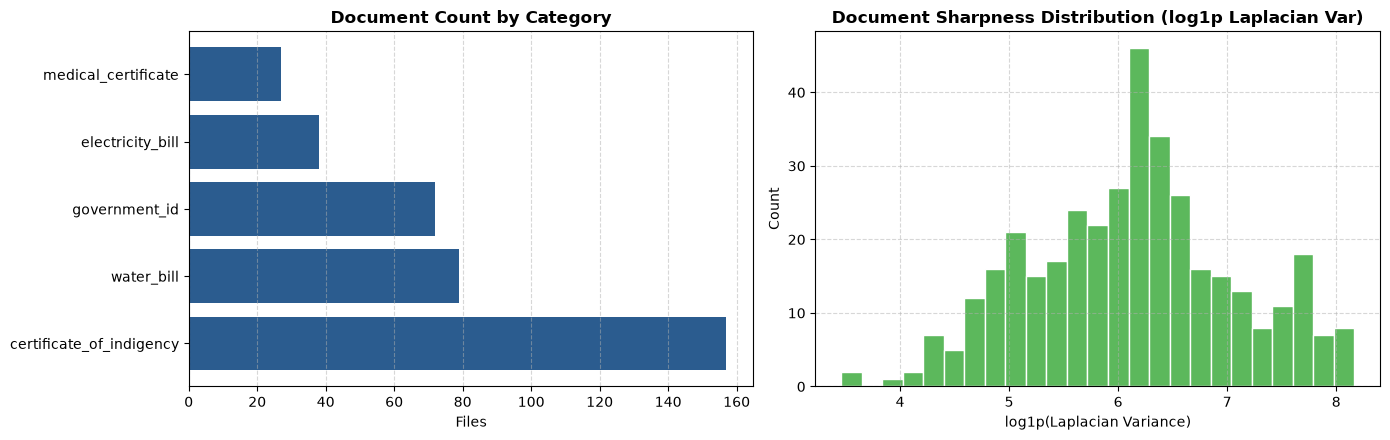

[OK] Saved quality audit JSON -> C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\document_quality_audit.json


In [3]:
if not df_inventory.empty:
    summary = {
        'audit_timestamp': datetime.now().isoformat(timespec='seconds'),
        'source_directory': str(paths.raw_documents_dir),
        'total_files_scanned': int(len(df_inventory)),
        'valid_files': int((df_inventory['validation_status'] == 'VALID').sum()),
        'low_resolution_files': int((df_inventory['validation_status'] == 'LOW_RESOLUTION').sum()),
        'invalid_or_unreadable_files': int((~df_inventory['is_readable']).sum()),
        'exact_duplicate_files': int(df_inventory['is_duplicate'].sum()),
        'categories': df_inventory['document_category'].value_counts().to_dict(),
        'extensions': df_inventory['file_extension'].value_counts().to_dict(),
    }
    with open(AUDIT_JSON, 'w', encoding='utf-8') as f:
        json.dump(summary, f, indent=2)

    print("=== DOCUMENT INVENTORY SUMMARY ===")
    display(pd.DataFrame([
        {'Metric': 'Total Files Scanned', 'Value': summary['total_files_scanned']},
        {'Metric': 'Valid Readable Files', 'Value': summary['valid_files']},
        {'Metric': 'Low Resolution Warnings', 'Value': summary['low_resolution_files']},
        {'Metric': 'Invalid / Unreadable Files', 'Value': summary['invalid_or_unreadable_files']},
        {'Metric': 'Exact SHA-256 Duplicates', 'Value': summary['exact_duplicate_files']},
    ]))

    print("\n=== CATEGORY BREAKDOWN ===")
    cat_tbl = (
        df_inventory.groupby('document_category')
        .agg(
            total_files=('document_id', 'count'),
            valid_files=('is_readable', 'sum'),
            duplicates=('is_duplicate', 'sum'),
            median_width=('width', 'median'),
            median_height=('height', 'median'),
            median_blur_var=('blur_laplacian_var', 'median'),
        )
        .reset_index()
    )
    display(cat_tbl)

    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    cat_counts = df_inventory['document_category'].value_counts()
    axes[0].barh(cat_counts.index, cat_counts.values, color='#2b5c8f')
    axes[0].set_title('Document Count by Category', fontweight='bold')
    axes[0].set_xlabel('Files')
    axes[0].grid(axis='x', linestyle='--', alpha=0.5)

    readable = df_inventory[df_inventory['is_readable'] & (df_inventory['blur_laplacian_var'] > 0)]
    if not readable.empty:
        axes[1].hist(np.log1p(readable['blur_laplacian_var']), bins=25, color='#5cb85c', edgecolor='white')
        axes[1].set_title('Document Sharpness Distribution (log1p Laplacian Var)', fontweight='bold')
        axes[1].set_xlabel('log1p(Laplacian Variance)')
        axes[1].set_ylabel('Count')
        axes[1].grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    print(f"[OK] Saved quality audit JSON -> {AUDIT_JSON}")
